# Why the literature predicts *lateness* — and what it misses
### Hidden Dissatisfaction · EDA report on the Olist Brazilian e-commerce dataset

**The question.** Published Olist models (Wong & Marikannan 2020; Wangkiat & Polprasert 2023; Bachir et al. 2024; Leite et al. 2024) all end up "discovering" that **late delivery drives bad reviews**. This notebook asks two things:

1. **Why** does every model converge on lateness? Is it the customer, the data, or the method?
2. **What does that leave out?** In particular: customers who are unhappy even though their order arrived **on time**. They are the target of the Hidden Dissatisfaction project, and they correspond to literature gaps **G1** (on-time-but-unhappy orders are never modelled) and **G4** (accuracy reported on imbalanced data).

**How to read it.** Each section ends with a *What we see → Why it matters* note, and each chart is followed by the table behind it.

| Term | Definition used in this notebook |
|---|---|
| Unit of analysis | one **delivered** order that has a customer review |
| Negative review | `review_score` of 1 or 2 stars |
| Late | delivery **date** is after the estimated delivery **date** (same-day delivery counts as on time) |
| On time | not late |
| Colours | **orange = late orders**, **blue = on-time orders**, **grey = all orders / context** |

In [1]:
import re
import unicodedata
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter
from IPython.display import display
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
DATA = Path("dataset")  # folder with the 9 Olist CSV files
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

# ---- chart style: light surface, recessive hairline axes, two fixed series colours --------------
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ONTIME, LATE, CONTEXT = "#2a78d6", "#eb6834", "#898781"  # blue = on time, orange = late, grey = all / other
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
BAR = dict(edgecolor=SURFACE, linewidth=1.5)          # surface-coloured gap between touching bars
DOT = dict(marker="o", ms=5.5, mec=SURFACE, mew=1.5)  # markers with a surface ring


def title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)


def pct_axis(ax, axis="y", decimals=0):
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))  # clean ticks: no 2.5% steps rounded to "2%"
    target.set_major_formatter(PercentFormatter(1, decimals=decimals))


def label_bars(ax, bars, values, fmt="{:.0%}", horizontal=False):
    """Value at the bar tip, written in text ink (never in the series colour)."""
    for b, v in zip(bars, values):
        if pd.isna(v):
            continue
        if horizontal:
            ax.annotate(fmt.format(v), (b.get_x() + b.get_width(), b.get_y() + b.get_height() / 2), xytext=(3, 0),
                        textcoords="offset points", ha="left", va="center", fontsize=8.5, color=INK2)
        else:
            ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color=INK2)


def ink_on(hex_color):
    """White or ink text for a label placed inside a coloured fill, whichever contrasts more."""
    rgb = [int(hex_color[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    lum = sum(w * (c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4) for w, c in zip((0.2126, 0.7152, 0.0722), rgb))
    return "white" if (1.05 / (lum + 0.05)) >= ((lum + 0.05) / 0.05) else INK


def show(df, pct=(), num=(), dec=3):
    """Display a table with readable number formats (no Styler/jinja2 needed)."""
    out = df.copy()
    for c in pct:
        out[c] = out[c].map(lambda v: "" if pd.isna(v) else f"{v:.1%}")
    for c in num:
        out[c] = out[c].map(lambda v: "" if pd.isna(v) else (f"{v:,.0f}" if float(v).is_integer() else f"{v:,.{dec}f}"))
    display(out)

numpy 2.5.3 | pandas 2.3.3 | scikit-learn 1.8.0 | matplotlib 3.11.0


## 1 · Build one row per delivered order

The nine Olist tables are joined into a single order-level table. Every feature below is **known when the order is delivered**, so none of them leaks the review. The review text and review timing are used later only to *explain* the label, never as predictors.

| Feature | Meaning | Known when? |
|---|---|---|
| `days_vs_estimate` | delivery date − estimated date, in days (negative = early) | at delivery |
| `is_late` | `days_vs_estimate > 0` | at delivery |
| `delivery_days` / `promised_days` | actual / promised days from purchase | at delivery / at purchase |
| `handoff_days`, `carrier_to_customer_days` | purchase → carrier, carrier → customer | at delivery |
| `dispatch_late` | seller handed to the carrier after its `shipping_limit_date` | at hand-off |
| `n_items`, `n_products`, `n_sellers` | size and "split" of the order | at purchase |
| `price`, `freight`, `freight_ratio`, `installments`, `payment_type` | money | at purchase |
| `distance_km` | seller ↔ customer distance (zip-prefix centroids) | at purchase |
| `seller_prior_neg_rate` | seller's share of 1–2★ among reviews **answered before this purchase** (≥ 5 reviews) | at purchase (point-in-time) |

In [2]:
orders = pd.read_csv(DATA / "olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
reviews = pd.read_csv(DATA / "olist_order_reviews_dataset.csv", parse_dates=["review_creation_date", "review_answer_timestamp"])
items = pd.read_csv(DATA / "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
products = pd.read_csv(DATA / "olist_products_dataset.csv")
customers = pd.read_csv(DATA / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
sellers = pd.read_csv(DATA / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
geo = pd.read_csv(DATA / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})
cat_en = pd.read_csv(DATA / "product_category_name_translation.csv")

# 1) one review per order: some orders have several review rows -> keep the most recent answer
reviews_1 = reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

# 2) items -> order level (the most expensive item defines the order's category and main seller)
it = items.merge(products, on="product_id", how="left").merge(cat_en, on="product_category_name", how="left")
order_items = it.groupby("order_id").agg(
    n_items=("order_item_id", "size"), n_products=("product_id", "nunique"), n_sellers=("seller_id", "nunique"),
    price=("price", "sum"), freight=("freight_value", "sum"), shipping_limit=("shipping_limit_date", "max"),
    photos=("product_photos_qty", "mean"), desc_len=("product_description_lenght", "mean"),
    weight_g=("product_weight_g", "sum")).reset_index()
main_item = (it.sort_values("price", ascending=False).drop_duplicates("order_id")
             [["order_id", "product_category_name_english", "seller_id"]]
             .rename(columns={"product_category_name_english": "category", "seller_id": "main_seller"}))

# 3) payments -> order level
order_pay = payments.groupby("order_id").agg(n_pay=("payment_sequential", "size"),
                                             installments=("payment_installments", "max")).reset_index()
main_pay = payments.sort_values("payment_value", ascending=False).drop_duplicates("order_id")[["order_id", "payment_type"]]

review_cols = ["order_id", "review_score", "review_comment_message", "review_creation_date", "review_answer_timestamp"]
df = (orders.merge(reviews_1[review_cols], on="order_id")  # inner join: reviewed orders only
      .merge(order_items, on="order_id", how="left").merge(main_item, on="order_id", how="left")
      .merge(order_pay, on="order_id", how="left").merge(main_pay, on="order_id", how="left")
      .merge(customers[["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_state"]],
             on="customer_id", how="left")
      .merge(sellers.rename(columns={"seller_id": "main_seller"}), on="main_seller", how="left"))

# 4) seller <-> customer distance from zip-prefix centroids (haversine, km)
centroid = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
c = centroid.reindex(df.customer_zip_code_prefix.to_numpy()).to_numpy()
s = centroid.reindex(df.seller_zip_code_prefix.to_numpy()).to_numpy()
lat1, lng1, lat2, lng2 = map(np.radians, (c[:, 0], c[:, 1], s[:, 0], s[:, 1]))
h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(h))

# 5) keep delivered orders that have a delivery date, then derive the timing features
d = df[(df.order_status == "delivered") & df.order_delivered_customer_date.notna()].copy()
day = pd.Timedelta(days=1)
d["days_vs_estimate"] = (d.order_delivered_customer_date.dt.normalize() - d.order_estimated_delivery_date).dt.days
d["is_late"] = d.days_vs_estimate > 0
d["timing"] = np.where(d.is_late, "Late", "On time")
d["negative"] = d.review_score <= 2
d["delivery_days"] = (d.order_delivered_customer_date - d.order_purchase_timestamp) / day
d["promised_days"] = (d.order_estimated_delivery_date - d.order_purchase_timestamp) / day
d["approval_hours"] = (d.order_approved_at - d.order_purchase_timestamp) / pd.Timedelta(hours=1)
d["handoff_days"] = (d.order_delivered_carrier_date - d.order_purchase_timestamp) / day
d["carrier_to_customer_days"] = (d.order_delivered_customer_date - d.order_delivered_carrier_date) / day
d["dispatch_late"] = d.order_delivered_carrier_date > d.shipping_limit
d["freight_ratio"] = d.freight / d.price
d["month"] = d.order_purchase_timestamp.dt.to_period("M")
# review-process fields: used ONLY to understand the label, never as model features
d["survey_sent_before_delivery"] = d.review_creation_date < d.order_delivered_customer_date.dt.normalize()
d["answered_before_delivery"] = d.review_answer_timestamp < d.order_delivered_customer_date
d["has_text"] = d.review_comment_message.notna()

# 6) point-in-time seller history: reviews answered BEFORE this order was placed (no look-ahead)
pairs = items[["order_id", "seller_id"]].drop_duplicates().merge(
    d[["order_id", "order_purchase_timestamp", "review_answer_timestamp", "negative"]], on="order_id")
events = pairs[["seller_id", "review_answer_timestamp", "negative"]].sort_values("review_answer_timestamp")
events["prior_n"] = events.groupby("seller_id").cumcount() + 1
events["prior_neg"] = events.groupby("seller_id").negative.cumsum()
queries = pairs[["order_id", "seller_id", "order_purchase_timestamp"]].sort_values("order_purchase_timestamp")
hist = pd.merge_asof(queries, events.drop(columns="negative"), left_on="order_purchase_timestamp",
                     right_on="review_answer_timestamp", by="seller_id", allow_exact_matches=False)
hist[["prior_n", "prior_neg"]] = hist[["prior_n", "prior_neg"]].fillna(0)
hist["rate"] = np.where(hist.prior_n >= 5, hist.prior_neg / hist.prior_n.clip(lower=1), np.nan)
d = d.merge(hist.groupby("order_id").agg(seller_prior_n=("prior_n", "min"), seller_prior_neg_rate=("rate", "max")),
            on="order_id", how="left")

on, late = d[~d.is_late], d[d.is_late]
funnel = pd.DataFrame({"orders": {
    "All orders in the dataset": len(orders),
    "…with at least one review": orders.order_id.isin(reviews.order_id).sum(),
    "…of which duplicate review rows removed": len(reviews) - len(reviews_1),
    "Delivered (status + delivery date), any review status": ((orders.order_status == "delivered")
                                                              & orders.order_delivered_customer_date.notna()).sum(),
    "Analysis table: delivered AND reviewed (1 review per order)": len(d)}})
show(funnel, num=["orders"])

,orders
All orders in the dataset,"99,441"
…with at least one review,"98,673"
…of which duplicate review rows removed,551
"Delivered (status + delivery date), any review status","96,470"
Analysis table: delivered AND reviewed (1 review per order),"95,824"


**Data-quality notes**
- 551 review rows are extra reviews for orders that already have one; the most recent answer is kept. 768 orders were never reviewed.
- The analysis table has **95,824 delivered and reviewed orders**. Orders that were never delivered (cancelled, unavailable, still shipping) are excluded because they have no delivery outcome.
- "Late" is measured at **day level**. The estimated date has no time of day, so a delivery at 18:00 on the estimated date counts as on time.

## 2 · The target at a glance

,value
Delivered & reviewed orders,"95,824"
Share of orders delivered late,6.7%
Negative (1–2★) rate: all orders,12.8%
Negative rate: on-time orders,9.3%
Negative rate: late orders,62.4%
Share of ALL negative reviews that come from on-time orders,67.5%
Customers with more than one order,3.0%


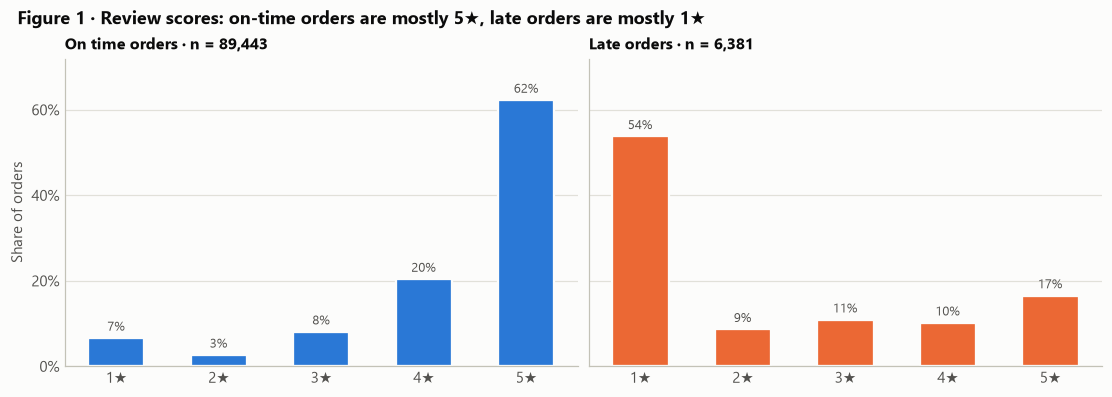

review_score,timing,1★,2★,3★,4★,5★
0,Late,53.8%,8.7%,10.9%,10.2%,16.5%
1,On time,6.6%,2.6%,8.1%,20.4%,62.3%


In [3]:
kpi = pd.DataFrame({"value": {
    "Delivered & reviewed orders": len(d),
    "Share of orders delivered late": d.is_late.mean(),
    "Negative (1–2★) rate: all orders": d.negative.mean(),
    "Negative rate: on-time orders": on.negative.mean(),
    "Negative rate: late orders": late.negative.mean(),
    "Share of ALL negative reviews that come from on-time orders": (~d.loc[d.negative, "is_late"]).mean(),
    "Customers with more than one order": (d.groupby("customer_unique_id").order_id.nunique() > 1).mean(),
}})
kpi["value"] = [f"{v:,.0f}" if v > 1 else f"{v:.1%}" for v in kpi.value]
display(kpi)

share = d.groupby("timing").review_score.value_counts(normalize=True).unstack().reindex(columns=[1, 2, 3, 4, 5])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for ax, name, color in zip(axes, ["On time", "Late"], [ONTIME, LATE]):
    bars = ax.bar([f"{k}★" for k in share.columns], share.loc[name], width=0.55, color=color, **BAR)
    label_bars(ax, bars, share.loc[name])
    ax.set_title(f"{name} orders · n = {(d.timing == name).sum():,}")
    pct_axis(ax)
    ax.set_ylim(0, 0.72)
axes[0].set_ylabel("Share of orders")
title(fig, "Figure 1 · Review scores: on-time orders are mostly 5★, late orders are mostly 1★")
plt.show()
show(share.rename(columns=lambda k: f"{k}★").reset_index(), pct=[f"{k}★" for k in range(1, 6)])

**What we see.** On-time orders show the usual J-shape: 62% are 5★ and only 9.3% are 1–2★. Late orders flip it: 54% are 1★ and 62% are negative. Late orders are only 6.7% of deliveries, but they are **6.7× more likely** to receive a negative review.

**Why it matters.** The target is imbalanced (12.8% negative overall, 9.3% among on-time orders), and one variable separates the two score distributions almost perfectly. Any model or EDA run on *all* orders will lock onto that variable first.

## 3 · Five reasons published models end up predicting lateness

### Reason 1: Lateness is the loudest signal, and it acts like a cliff

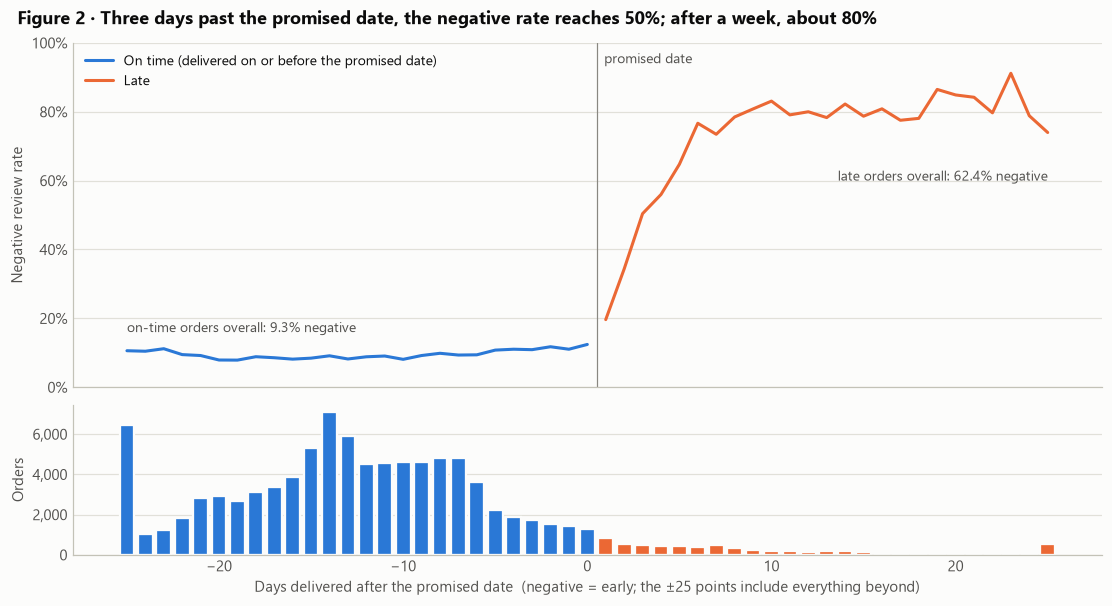

,days_vs_estimate,orders,negative_rate
0,-25,"6,455",10.6%
1,-24,"1,062",10.5%
2,-23,"1,252",11.2%
3,-22,"1,837",9.5%
4,-21,"2,803",9.2%
5,-20,"2,949",7.9%
6,-19,"2,693",7.9%
7,-18,"3,116",8.9%
8,-17,"3,398",8.6%
9,-16,"3,888",8.2%


In [4]:
by_day = (d.assign(dv=d.days_vs_estimate.clip(-25, 25)).groupby("dv")
          .agg(orders=("negative", "size"), negative_rate=("negative", "mean")))
by_day = by_day[by_day.orders >= 30]
early, tardy = by_day[by_day.index <= 0], by_day[by_day.index > 0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True, height_ratios=[2.3, 1], layout="constrained")
ax1.plot(early.index, early.negative_rate, color=ONTIME, label="On time (delivered on or before the promised date)")
ax1.plot(tardy.index, tardy.negative_rate, color=LATE, label="Late")
ax1.axvline(0.5, color=MUTED, lw=0.8)
ax1.annotate("promised date", (0.5, 0.97), xycoords=("data", "axes fraction"), xytext=(5, 0),
             textcoords="offset points", va="top", fontsize=9, color=INK2)
ax1.annotate(f"on-time orders overall: {on.negative.mean():.1%} negative", (-25, 0.16), fontsize=9, color=INK2)
ax1.annotate(f"late orders overall: {late.negative.mean():.1%} negative", (25, 0.60), ha="right", fontsize=9, color=INK2)
ax1.set_ylabel("Negative review rate")
ax1.set_ylim(0, 1)
pct_axis(ax1)
ax1.legend(loc="upper left")
ax2.bar(by_day.index, by_day.orders, width=0.8, color=[ONTIME if x <= 0 else LATE for x in by_day.index], **BAR)
ax2.set_ylabel("Orders")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax2.set_xlabel("Days delivered after the promised date  (negative = early; the ±25 points include everything beyond)")
title(fig, "Figure 2 · Three days past the promised date, the negative rate reaches 50%; after a week, about 80%")
plt.show()
show(by_day.reset_index().rename(columns={"dv": "days_vs_estimate"}), pct=["negative_rate"], num=["orders"])

**What we see.** Deliveries 1–25 days early all sit near 8–12% negative. **Once the promised date passes, the rate climbs quickly**: 20% one day late, 50% three days late, and about 80% after a week. Arriving *earlier* than promised helps very little, while arriving *later* is punished heavily. This is the asymmetry Ravula (2022) reports on the same data.

**Why it matters.** A step function this sharp is easy for any tree model to find, so it becomes the top "driver" in every paper.

### Reason 2: For late orders, the survey arrives before the parcel

Olist's own documentation says the survey is emailed *"once the customer receives the product, **or the estimated delivery date is due**."* So when an order is late, the customer is asked to rate a purchase they have not received yet.

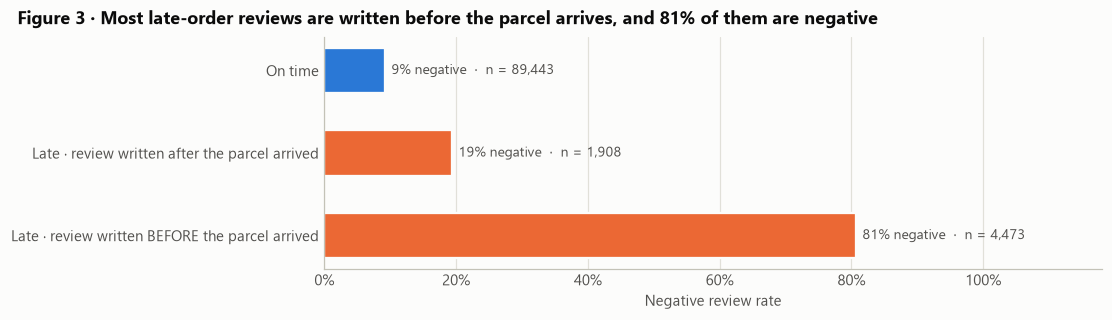

Late orders whose review was answered before delivery: 70.1% (survey e-mailed before delivery: 74.5%; on-time orders: 0.3%)


,group,orders,negative_rate,survey_sent_before_delivery
0,On time,"89,443",9.3%,0.3%
1,Late · review written after the parcel arrived,"1,908",19.4%,24.9%
2,Late · review written BEFORE the parcel arrived,"4,473",80.8%,95.6%


In [5]:
group = pd.Series(np.select(
    [~d.is_late, d.is_late & ~d.answered_before_delivery, d.is_late & d.answered_before_delivery],
    ["On time", "Late · review written after the parcel arrived", "Late · review written BEFORE the parcel arrived"],
    default=""), index=d.index)
order3 = ["On time", "Late · review written after the parcel arrived", "Late · review written BEFORE the parcel arrived"]
t3 = d.groupby(group).agg(orders=("negative", "size"), negative_rate=("negative", "mean"),
                          survey_sent_before_delivery=("survey_sent_before_delivery", "mean")).reindex(order3)

fig, ax = plt.subplots(figsize=(10, 2.8), layout="constrained")
bars = ax.barh(t3.index[::-1], t3.negative_rate[::-1], height=0.55, color=[LATE, LATE, ONTIME], **BAR)
for b, (_, r) in zip(bars, t3[::-1].iterrows()):
    ax.annotate(f"{r.negative_rate:.0%} negative  ·  n = {r.orders:,.0f}", (b.get_width(), b.get_y() + b.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1.18)
pct_axis(ax, "x")
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Negative review rate")
title(fig, "Figure 3 · Most late-order reviews are written before the parcel arrives, and 81% of them are negative")
plt.show()
print(f"Late orders whose review was answered before delivery: {late.answered_before_delivery.mean():.1%} "
      f"(survey e-mailed before delivery: {late.survey_sent_before_delivery.mean():.1%}; on-time orders: "
      f"{on.survey_sent_before_delivery.mean():.1%})")
show(t3.reset_index(names="group"), pct=["negative_rate", "survey_sent_before_delivery"], num=["orders"])

**What we see.** 70% of late-order reviews were answered **before the parcel arrived**, and 81% of those are negative. Late orders reviewed *after* arrival are much milder (19% negative, still about twice the on-time rate).

**Why it matters.** For most late orders the "review" is really a *where-is-my-parcel* complaint that the survey schedule produces automatically. Predicting it from timestamps is close to predicting the survey rules. It inflates the importance of lateness and the headline accuracy in the papers, and it says little about how satisfied customers are with what they received.

### Reason 3: Lateness drives the ups and downs over time

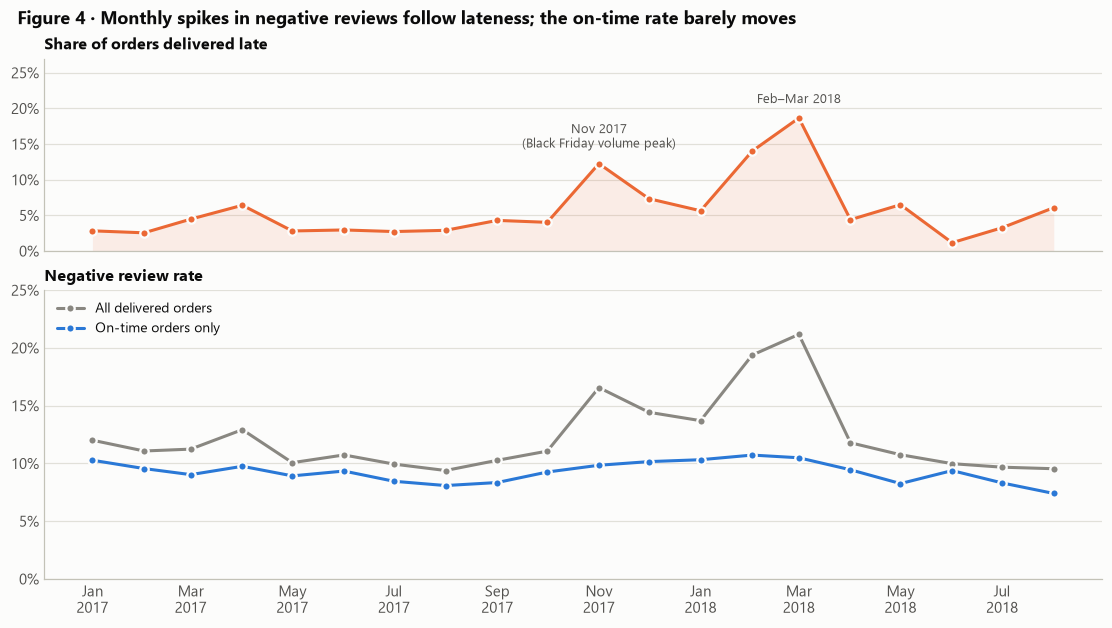

,month,orders,late_share,negative_all,negative_on_time
0,2017-01,741,2.8%,12.0%,10.3%
1,2017-02,"1,643",2.6%,11.1%,9.6%
2,2017-03,"2,527",4.5%,11.2%,9.0%
3,2017-04,"2,290",6.4%,12.9%,9.8%
4,2017-05,"3,517",2.8%,10.1%,8.9%
5,2017-06,"3,111",3.0%,10.7%,9.3%
6,2017-07,"3,842",2.7%,9.9%,8.5%
7,2017-08,"4,165",2.9%,9.4%,8.1%
8,2017-09,"4,118",4.3%,10.3%,8.3%
9,2017-10,"4,446",4.0%,11.1%,9.3%


In [6]:
monthly = d.groupby("month").agg(orders=("negative", "size"), late_share=("is_late", "mean"), negative_all=("negative", "mean"))
monthly["negative_on_time"] = on.groupby("month").negative.mean()
monthly = monthly[monthly.orders >= 500]
x = monthly.index.to_timestamp()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, height_ratios=[1, 1.5], layout="constrained")
a1.plot(x, monthly.late_share, color=LATE, **DOT)
a1.fill_between(x, monthly.late_share, color=LATE, alpha=0.10, lw=0)
a1.set_title("Share of orders delivered late")
pct_axis(a1)
a1.set_ylim(0, 0.27)
for when, txt in [("2017-11", "Nov 2017\n(Black Friday volume peak)"), ("2018-03", "Feb–Mar 2018")]:
    t = pd.Period(when, "M")
    a1.annotate(txt, (t.to_timestamp(), monthly.loc[t, "late_share"]), xytext=(0, 8), textcoords="offset points",
                ha="center", va="bottom", fontsize=8.5, color=INK2)
a2.plot(x, monthly.negative_all, color=CONTEXT, label="All delivered orders", **DOT)
a2.plot(x, monthly.negative_on_time, color=ONTIME, label="On-time orders only", **DOT)
a2.set_title("Negative review rate")
pct_axis(a2)
a2.set_ylim(0, 0.25)
a2.legend(loc="upper left")
a2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
title(fig, "Figure 4 · Monthly spikes in negative reviews follow lateness; the on-time rate barely moves")
plt.show()
show(monthly.reset_index().astype({"month": str}), pct=["late_share", "negative_all", "negative_on_time"], num=["orders"])

**What we see.** The overall negative rate swings between about 9% and 21%, and each swing lines up with a lateness spike (Nov 2017, and Feb–Mar 2018 when 14–19% of orders were late). The **on-time** negative rate stays in a narrow 7–11% band throughout.

**Why it matters.** Anyone who looks at the dataset over time sees lateness first. The on-time-but-unhappy customers are a steady baseline that never shows up as a spike, which is exactly what makes them *hidden*.

### Reason 4: Timing features top the single-feature ranking, then fade on on-time orders

Each feature is scored on its own with ROC-AUC (0.5 = no signal). Direction is ignored, so a feature that *lowers* risk scores the same as one that raises it.

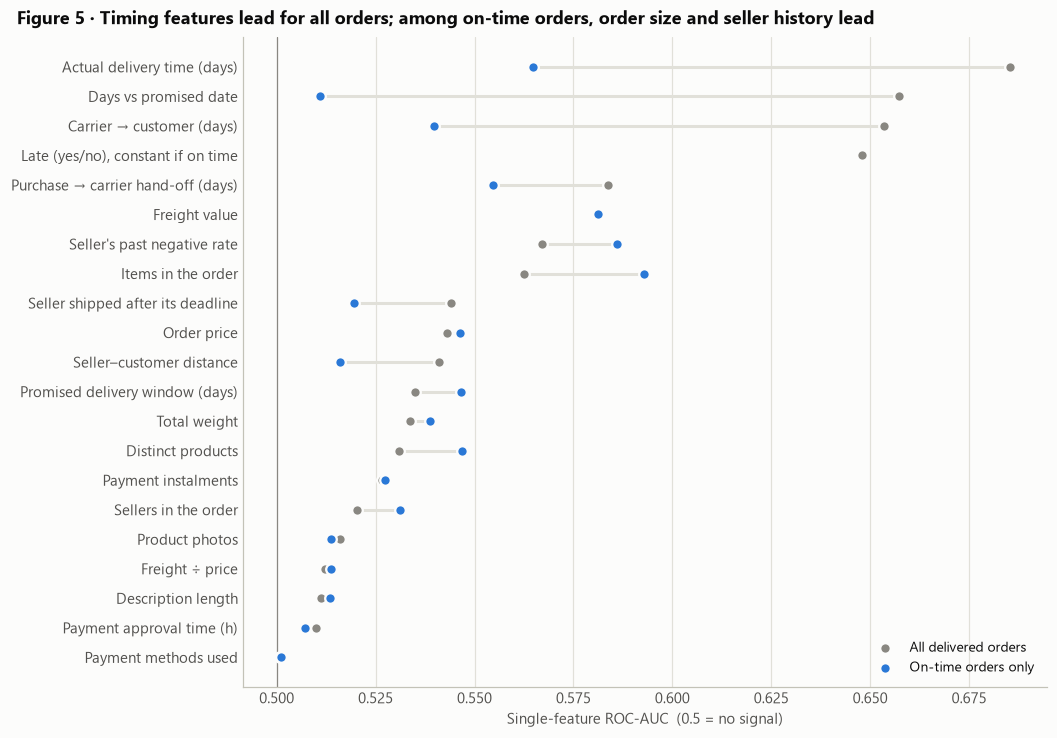

,feature,all_orders,on_time_only
0,Actual delivery time (days),0.685,0.565
1,Days vs promised date,0.657,0.511
2,Carrier → customer (days),0.654,0.540
3,"Late (yes/no), constant if on time",0.648,
4,Purchase → carrier hand-off (days),0.584,0.555
5,Freight value,0.581,0.581
6,Seller's past negative rate,0.567,0.586
7,Items in the order,0.563,0.593
8,Seller shipped after its deadline,0.544,0.520
9,Order price,0.543,0.546


In [7]:
LABELS = {
    "delivery_days": "Actual delivery time (days)", "days_vs_estimate": "Days vs promised date",
    "carrier_to_customer_days": "Carrier → customer (days)", "is_late": "Late (yes/no), constant if on time",
    "handoff_days": "Purchase → carrier hand-off (days)", "freight": "Freight value",
    "seller_prior_neg_rate": "Seller's past negative rate", "n_items": "Items in the order",
    "dispatch_late": "Seller shipped after its deadline", "price": "Order price",
    "distance_km": "Seller–customer distance", "promised_days": "Promised delivery window (days)",
    "weight_g": "Total weight", "n_products": "Distinct products", "installments": "Payment instalments",
    "n_sellers": "Sellers in the order", "photos": "Product photos", "freight_ratio": "Freight ÷ price",
    "desc_len": "Description length", "approval_hours": "Payment approval time (h)", "n_pay": "Payment methods used",
    "seller_prior_n": "Seller's past review count", "category": "Product category",
    "customer_state": "Customer state", "payment_type": "Payment type",
}
TIMING = {"delivery_days", "days_vs_estimate", "carrier_to_customer_days", "is_late", "handoff_days",
          "promised_days", "dispatch_late"}


def auc_free(y, x):
    ok = x.notna()
    if x[ok].nunique() < 2:
        return np.nan
    a = roc_auc_score(y[ok].astype(int), x[ok].astype(float))
    return max(a, 1 - a)


feats = [f for f in LABELS if f not in ("seller_prior_n", "category", "customer_state", "payment_type")]
auc = pd.DataFrame({"all_orders": [auc_free(d.negative, d[f]) for f in feats],
                    "on_time_only": [auc_free(on.negative, on[f]) for f in feats]}, index=feats).sort_values("all_orders")

fig, ax = plt.subplots(figsize=(9.5, 6.6), layout="constrained")
yy = np.arange(len(auc))
for i, (a, o) in enumerate(zip(auc.all_orders, auc.on_time_only)):
    if pd.notna(o):
        ax.plot([a, o], [i, i], color=GRID, lw=2, zorder=1)
ax.scatter(auc.all_orders, yy, s=48, color=CONTEXT, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="All delivered orders")
ax.scatter(auc.on_time_only, yy, s=48, color=ONTIME, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="On-time orders only")
ax.set_yticks(yy, [LABELS[f] for f in auc.index])
ax.axvline(0.5, color=MUTED, lw=0.8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Single-feature ROC-AUC  (0.5 = no signal)")
ax.legend(loc="lower right")
title(fig, "Figure 5 · Timing features lead for all orders; among on-time orders, order size and seller history lead")
plt.show()
show(auc.sort_values("all_orders", ascending=False).rename(index=LABELS).reset_index(names="feature"),
     num=["all_orders", "on_time_only"])

**What we see.** On all orders the top four are all **timing** features (AUC 0.65–0.69). Restricted to on-time orders they drop to 0.51–0.57. **Items in the order (0.59), the seller's past negative rate (0.59) and freight (0.58)** take the lead instead.

**Why it matters.** The "drivers" a paper reports depend on *which orders it models*. Fit on everything and the timing features win. The on-time segment has different and weaker signals, so it needs its own model and its own features.

### Reason 5: The metric trap, where accuracy looks great and the model only finds late orders

To see what a typical paper's model learns, the next cell fits a gradient-boosting classifier the way those papers do: **all delivered orders, random 70/30 split, default threshold 0.5**. A second model is fitted on **on-time orders only**, which is the Hidden Dissatisfaction setting. This is a *diagnostic*, not a tuned benchmark.

In [8]:
NUM = ["delivery_days", "days_vs_estimate", "promised_days", "handoff_days", "carrier_to_customer_days", "approval_hours",
       "n_items", "n_products", "n_sellers", "price", "freight", "freight_ratio", "distance_km", "installments", "n_pay",
       "photos", "desc_len", "weight_g", "seller_prior_neg_rate", "seller_prior_n"]
BIN, CAT = ["is_late", "dispatch_late"], ["category", "customer_state", "payment_type"]
X = d[NUM + BIN + CAT].copy()
X[BIN] = X[BIN].astype(float)
for col in CAT:
    X[col] = X[col].astype("category")
y = d.negative.astype(int).to_numpy()
late_flag = d.is_late.to_numpy()


def diagnose(mask, drop=()):
    cols = [col for col in X.columns if col not in drop]
    Xtr, Xte, ytr, yte, _, late_te = train_test_split(X.loc[mask, cols], y[mask], late_flag[mask], test_size=0.3,
                                                      stratify=y[mask], random_state=42)
    model = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=42).fit(Xtr, ytr)
    p = model.predict_proba(Xte)[:, 1]
    top = np.zeros(len(p), bool)
    top[np.argsort(-p)[: int(0.10 * len(p))]] = True  # the 10% highest-risk orders = a fixed "contact budget"
    pi = permutation_importance(model, Xte, yte, scoring="average_precision", n_repeats=5, random_state=0)
    return dict(yte=yte, late_te=late_te, p=p, top=top, imp=pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False))


def scores(name, pop, yte, pred, p=None):
    r = {"model": name, "evaluated on": pop, "accuracy": accuracy_score(yte, pred),
         "precision": precision_score(yte, pred) if pred.any() else np.nan, "recall": recall_score(yte, pred)}
    if p is not None:
        top = np.argsort(-p)[: int(0.10 * len(p))]
        r.update({"PR-AUC": average_precision_score(yte, p), "precision @ top 10%": yte[top].mean(),
                  "recall @ top 10%": yte[top].sum() / yte.sum()})
    return r


A = diagnose(np.ones(len(d), bool))              # typical paper: all delivered orders
B = diagnose(~late_flag, drop=("is_late",))      # Hidden Dissatisfaction: on-time orders only
metrics = pd.DataFrame([
    scores("Always predict 'not negative'", "all orders", A["yte"], np.zeros_like(A["yte"])),
    scores("Rule: late ⇒ negative", "all orders", A["yte"], A["late_te"].astype(int)),
    scores("Gradient boosting (typical paper)", "all orders", A["yte"], (A["p"] >= 0.5).astype(int), A["p"]),
    scores("Always predict 'not negative'", "on-time orders", B["yte"], np.zeros_like(B["yte"])),
    scores("Gradient boosting (on-time only)", "on-time orders", B["yte"], (B["p"] >= 0.5).astype(int), B["p"]),
])
show(metrics, pct=["accuracy", "precision", "recall", "precision @ top 10%", "recall @ top 10%"], num=["PR-AUC"])
print(f"Base rates in the test sets: all orders {A['yte'].mean():.1%}, on-time orders {B['yte'].mean():.1%}")
print(f"Share of the typical model's top-10% list that are LATE orders: {A['late_te'][A['top']].mean():.1%} "
      f"(late orders are {A['late_te'].mean():.1%} of the test set)")

,model,evaluated on,accuracy,precision,recall,PR-AUC,precision @ top 10%,recall @ top 10%
0,Always predict 'not negative',all orders,87.2%,,0.0%,,,
1,Rule: late ⇒ negative,all orders,89.0%,63.3%,32.9%,,,
2,Gradient boosting (typical paper),all orders,89.8%,74.6%,30.4%,0.482,55.0%,42.9%
3,Always predict 'not negative',on-time orders,90.7%,,0.0%,,,
4,Gradient boosting (on-time only),on-time orders,90.7%,56.5%,0.5%,0.232,27.8%,30.0%


Base rates in the test sets: all orders 12.8%, on-time orders 9.3%
Share of the typical model's top-10% list that are LATE orders: 58.7% (late orders are 6.7% of the test set)


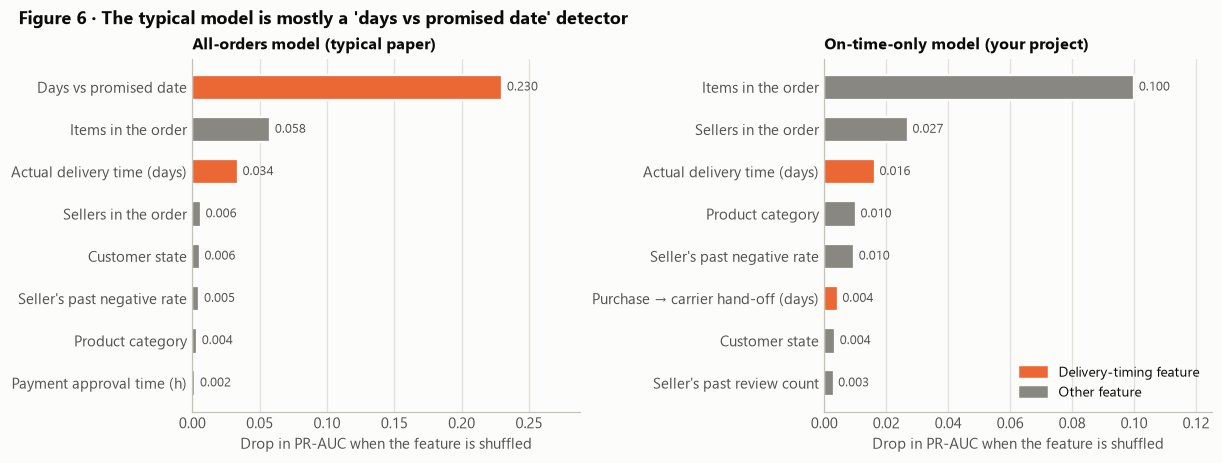

,all-orders model: feature,all-orders: PR-AUC drop,on-time model: feature,on-time: PR-AUC drop
0,Days vs promised date,0.230,Items in the order,0.100
1,Items in the order,0.058,Sellers in the order,0.027
2,Actual delivery time (days),0.034,Actual delivery time (days),0.016
3,Sellers in the order,0.006,Product category,0.010
4,Customer state,0.006,Seller's past negative rate,0.010
5,Seller's past negative rate,0.005,Purchase → carrier hand-off (days),0.004
6,Product category,0.004,Customer state,0.004
7,Payment approval time (h),0.002,Seller's past review count,0.003
8,Total weight,0.001,Promised delivery window (days),0.003
9,Seller's past review count,0.001,Seller–customer distance,0.002


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
for ax, res, name in [(axes[0], A, "All-orders model (typical paper)"), (axes[1], B, "On-time-only model (your project)")]:
    imp = res["imp"].head(8)[::-1]
    bars = ax.barh([LABELS.get(f, f) for f in imp.index], imp.values, height=0.6,
                   color=[LATE if f in TIMING else CONTEXT for f in imp.index], **BAR)
    label_bars(ax, bars, imp.values, fmt="{:.3f}", horizontal=True)
    ax.set_xlim(0, imp.max() * 1.25)
    ax.set_title(name)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
axes[1].legend(handles=[Patch(color=LATE, label="Delivery-timing feature"), Patch(color=CONTEXT, label="Other feature")],
               loc="lower right")
title(fig, "Figure 6 · The typical model is mostly a 'days vs promised date' detector")
plt.show()
show(pd.DataFrame({
    "all-orders model: feature": [LABELS.get(f, f) for f in A["imp"].head(10).index],
    "all-orders: PR-AUC drop": A["imp"].head(10).to_numpy(),
    "on-time model: feature": [LABELS.get(f, f) for f in B["imp"].head(10).index],
    "on-time: PR-AUC drop": B["imp"].head(10).to_numpy()}), num=["all-orders: PR-AUC drop", "on-time: PR-AUC drop"])

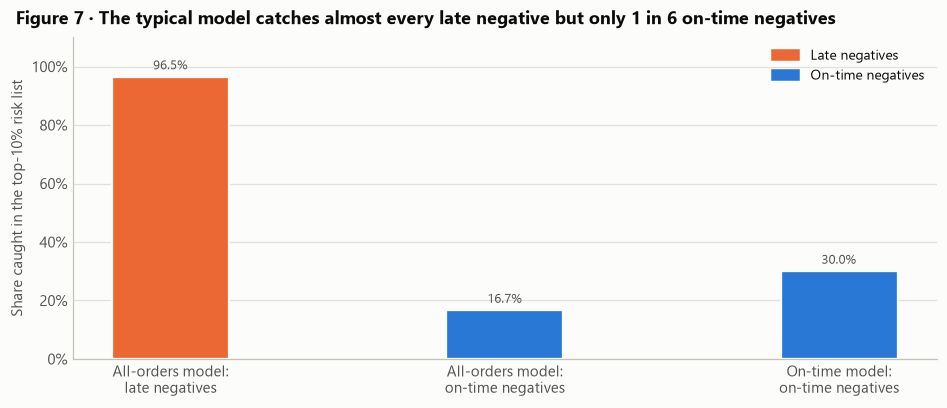

,group,negatives_in_test,share_caught_in_top_10pct
0,All-orders model: late negatives,"1,211",96.5%
1,All-orders model: on-time negatives,"2,471",16.7%
2,On-time model: on-time negatives,"2,487",30.0%


In [10]:
caught = pd.DataFrame({
    "group": ["All-orders model:\nlate negatives", "All-orders model:\non-time negatives", "On-time model:\non-time negatives"],
    "negatives_in_test": [(A["late_te"] & (A["yte"] == 1)).sum(), (~A["late_te"] & (A["yte"] == 1)).sum(), (B["yte"] == 1).sum()],
    "share_caught_in_top_10pct": [A["top"][A["late_te"] & (A["yte"] == 1)].mean(),
                                  A["top"][~A["late_te"] & (A["yte"] == 1)].mean(),
                                  B["top"][B["yte"] == 1].mean()]})
fig, ax = plt.subplots(figsize=(8.5, 3.6), layout="constrained")
bars = ax.bar(caught.group, caught.share_caught_in_top_10pct, width=0.35, color=[LATE, ONTIME, ONTIME], **BAR)
label_bars(ax, bars, caught.share_caught_in_top_10pct, fmt="{:.1%}")
ax.set_ylim(0, 1.1)
pct_axis(ax)
ax.set_ylabel("Share caught in the top-10% risk list")
ax.legend(handles=[Patch(color=LATE, label="Late negatives"), Patch(color=ONTIME, label="On-time negatives")], loc="upper right")
title(fig, "Figure 7 · The typical model catches almost every late negative but only 1 in 6 on-time negatives")
plt.show()
show(caught.assign(group=caught.group.str.replace("\n", " ")), pct=["share_caught_in_top_10pct"], num=["negatives_in_test"])

**What we see.**
- **Accuracy barely beats doing nothing.** The typical model reaches 89.8% accuracy. That is only 2.6 points above "always predict not negative" (87.2%) and 0.8 points above the one-line rule *late ⇒ negative* (89.0%). The on-time model's accuracy (90.7%) is *identical* to its do-nothing baseline, because at the 0.5 threshold it flags almost no one. Judged by accuracy it looks useless.
- **Ranking metrics tell a different story.** The on-time model's PR-AUC is 0.23, about 2.5× the 9.3% base rate. Its top-10% list is 28% negative (3× random) and catches 30% of on-time negatives.
- **The typical model is a lateness detector.** One timing feature (`days_vs_estimate`) accounts for most of its PR-AUC. 59% of its top-10% list are late orders, although late orders are only 6.7% of the test set. It catches 96.5% of late negatives and just 16.7% of on-time negatives.

**Why it matters (G4).** Accuracy at a 0.5 threshold is the wrong yardstick for a 9–13% positive class: it rewards predicting "happy" for everyone. For a Customer Experience team with a fixed number of calls, the relevant numbers are **PR-AUC, precision/recall at the contact budget (top-k), and calibration** of the 0–100% risk score. These are the metrics the imbalanced-learning literature recommends (Saito & Rehmsmeier 2015; Neslin et al. 2006; van den Goorbergh et al. 2022).

## 4 · The hidden segment: on-time but unhappy

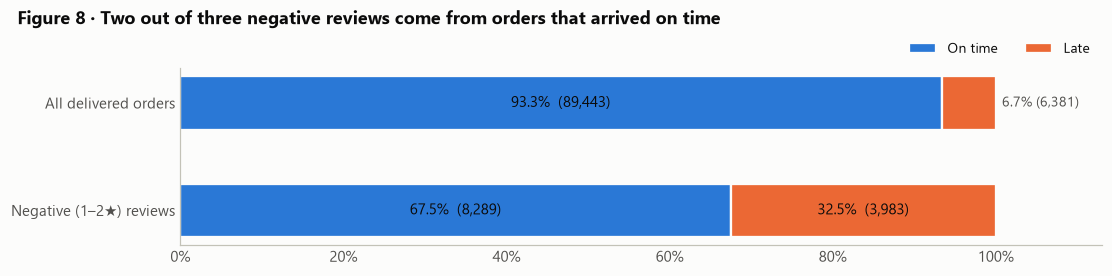

,population,On time,Late,total
0,All delivered orders,"89,443","6,381","95,824"
1,Negative (1–2★) reviews,"8,289","3,983","12,272"


In [11]:
parts = pd.DataFrame({
    "On time": [(~d.is_late).mean(), (~d.loc[d.negative, "is_late"]).mean()],
    "Late": [d.is_late.mean(), d.loc[d.negative, "is_late"].mean()]},
    index=["All delivered orders", "Negative (1–2★) reviews"])
counts = pd.DataFrame({"On time": [len(on), on.negative.sum()], "Late": [len(late), late.negative.sum()]}, index=parts.index)

fig, ax = plt.subplots(figsize=(10, 2.4), layout="constrained")
left = np.zeros(len(parts))
for col, color in [("On time", ONTIME), ("Late", LATE)]:
    bars = ax.barh(parts.index[::-1], parts[col][::-1], left=left, height=0.5, color=color, label=col, **BAR)
    for b, v, n, l0 in zip(bars, parts[col][::-1], counts[col][::-1], left):
        yc = b.get_y() + b.get_height() / 2
        if v > 0.15:
            ax.text(l0 + v / 2, yc, f"{v:.1%}  ({n:,})", ha="center", va="center", fontsize=9.5, color=ink_on(color))
        else:
            ax.annotate(f"{v:.1%} ({n:,})", (l0 + v, yc), xytext=(4, 0), textcoords="offset points", va="center",
                        fontsize=9, color=INK2)
    left += parts[col][::-1].to_numpy()
ax.set_xlim(0, 1.13)
pct_axis(ax, "x")
ax.grid(False)
ax.legend(ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))
title(fig, "Figure 8 · Two out of three negative reviews come from orders that arrived on time")
plt.show()
show(counts.assign(total=counts.sum(axis=1)).reset_index(names="population"), num=["On time", "Late", "total"])

**What we see.** Late orders are 6.7% of deliveries but 32.5% of negative reviews. The remaining **67.5% of negative reviews (8,289 orders) come from orders that arrived on time**. A logistics KPI dashboard never flags these orders.

The next figure looks only at **on-time orders** and asks what their negative reviews have in common. The grey line in each panel is the on-time average (9.3%). The y-axes differ between panels.

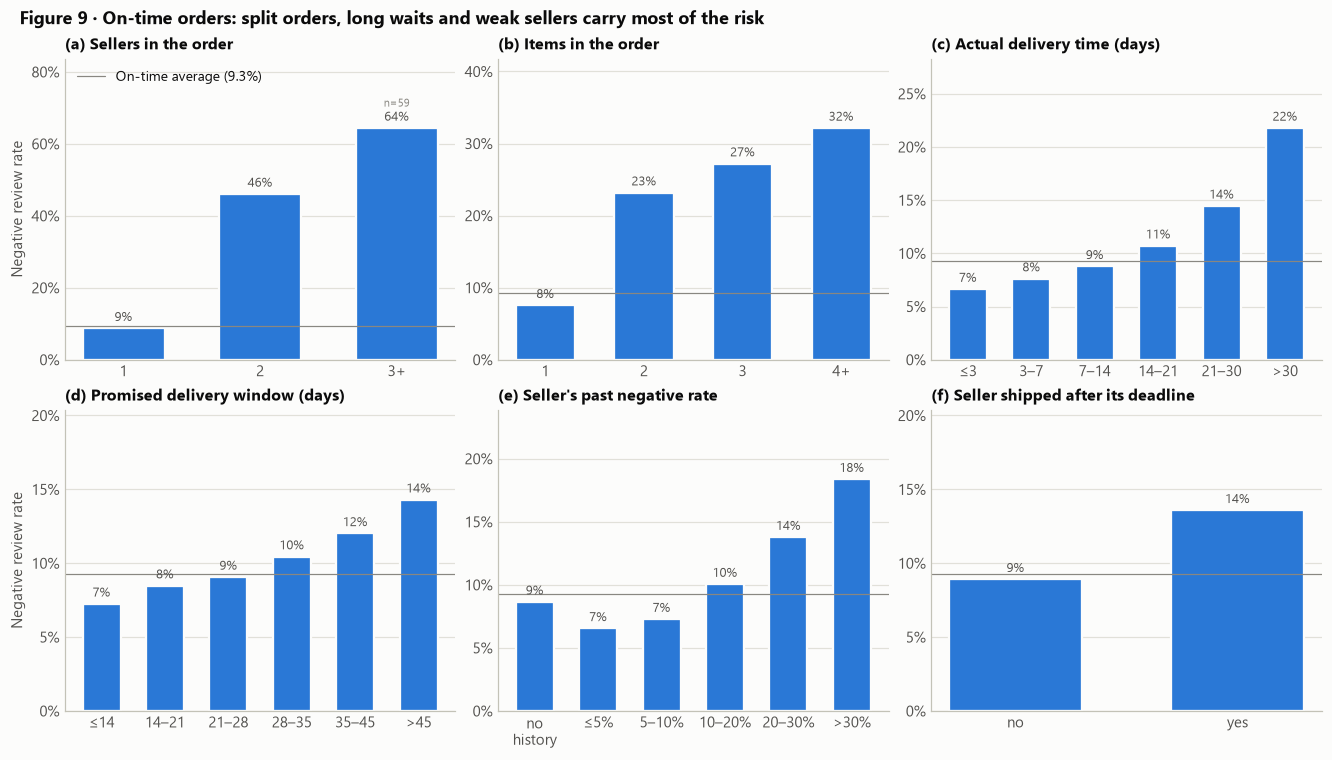

,factor,group,orders,negative_rate
0,(a) Sellers in the order,1,"88,194",8.7%
1,(a) Sellers in the order,2,"1,190",46.1%
2,(a) Sellers in the order,3+,59,64.4%
3,(b) Items in the order,1,"80,407",7.5%
4,(b) Items in the order,2,"6,935",23.2%
5,(b) Items in the order,3,"1,224",27.2%
6,(b) Items in the order,4+,877,32.2%
7,(c) Actual delivery time (days),≤3,"4,733",6.6%
8,(c) Actual delivery time (days),3–7,"21,142",7.6%
9,(c) Actual delivery time (days),7–14,"39,684",8.8%


In [12]:
def rate_by(frame, key, order):
    return frame.groupby(key, observed=True).negative.agg(orders="size", negative_rate="mean").reindex(order)


panels = [
    ("(a) Sellers in the order", rate_by(on, on.n_sellers.clip(upper=3).map({1: "1", 2: "2", 3: "3+"}), ["1", "2", "3+"])),
    ("(b) Items in the order", rate_by(on, on.n_items.clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4+"}), ["1", "2", "3", "4+"])),
    ("(c) Actual delivery time (days)", rate_by(on, pd.cut(on.delivery_days, [0, 3, 7, 14, 21, 30, np.inf],
                                                          labels=["≤3", "3–7", "7–14", "14–21", "21–30", ">30"]),
                                                ["≤3", "3–7", "7–14", "14–21", "21–30", ">30"])),
    ("(d) Promised delivery window (days)", rate_by(on, pd.cut(on.promised_days, [0, 14, 21, 28, 35, 45, np.inf],
                                                              labels=["≤14", "14–21", "21–28", "28–35", "35–45", ">45"]),
                                                    ["≤14", "14–21", "21–28", "28–35", "35–45", ">45"])),
    ("(e) Seller's past negative rate", rate_by(on, pd.cut(on.seller_prior_neg_rate, [-0.001, 0.05, 0.10, 0.20, 0.30, 1.0],
                                                           labels=["≤5%", "5–10%", "10–20%", "20–30%", ">30%"])
                                               .cat.add_categories("no\nhistory").fillna("no\nhistory"),
                                               ["no\nhistory", "≤5%", "5–10%", "10–20%", "20–30%", ">30%"])),
    ("(f) Seller shipped after its deadline", rate_by(on, on.dispatch_late.map({False: "no", True: "yes"}), ["no", "yes"])),
]
avg = on.negative.mean()
fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), layout="constrained")
for ax, (name, t) in zip(axes.ravel(), panels):
    bars = ax.bar(t.index.astype(str), t.negative_rate, width=0.6, color=ONTIME, **BAR)
    label_bars(ax, bars, t.negative_rate)
    for b, n in zip(bars, t.orders):
        if n < 500:  # flag small groups
            ax.annotate(f"n={n:,.0f}", (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 14),
                        textcoords="offset points", ha="center", fontsize=7.5, color=MUTED)
    ax.axhline(avg, color=MUTED, lw=0.8)
    ax.set_ylim(0, max(t.negative_rate.max() * 1.3, avg * 2.2))
    ax.set_title(name)
    pct_axis(ax)
axes[0, 0].legend(handles=[Line2D([], [], color=MUTED, lw=0.8, label=f"On-time average ({avg:.1%})")], loc="upper left")
axes[0, 0].set_ylabel("Negative review rate")
axes[1, 0].set_ylabel("Negative review rate")
title(fig, "Figure 9 · On-time orders: split orders, long waits and weak sellers carry most of the risk")
plt.show()
show(pd.concat({name: t for name, t in panels}).reset_index(names=["factor", "group"])
     .assign(group=lambda x: x.group.astype(str).str.replace("\n", " ")), pct=["negative_rate"], num=["orders"])

**What we see (on-time orders only).**
- **(a–b) Split orders are the strongest single signal.** Orders with 2 sellers have a **46% negative rate**, five times the single-seller rate and close to the rate for *late* orders. Multi-item orders go from 7.5% (1 item) to 32% (4+ items).
- **(c–d) "On time" is not the same as "fast".** An on-time order that took more than 30 days is 22% negative, against 6.6% for 3 days or less. Longer *promised* windows carry more risk too (7% → 14%). The customer judges the wait itself, not only whether the promise was kept (expectation–disconfirmation; Oliver 1980).
- **(e) Seller history carries over.** Sellers whose earlier reviews were >30% negative produce 18% negatives on on-time orders, against 6.5% for sellers at ≤5%.
- **(f) A seller who shipped late but still arrived on time** has a 13.6% negative rate, against 8.9% otherwise.

**Why it matters (G1).** All of these are known **at delivery time**, before the review exists. That is exactly what a proactive "Contact customer" list needs.

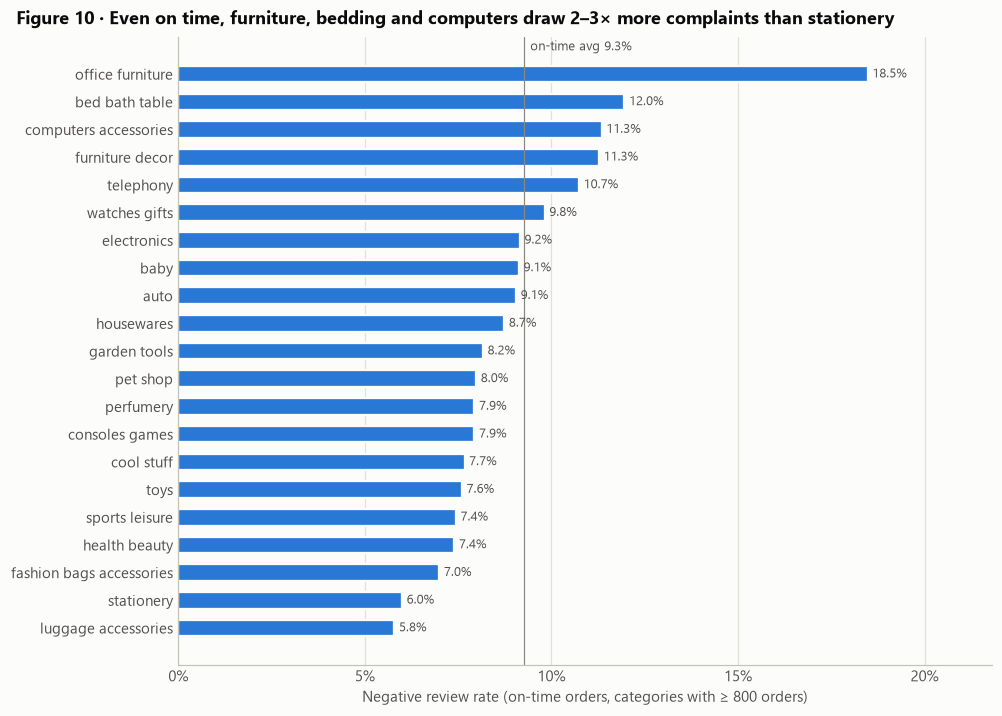

,category,orders,negative_rate
0,office_furniture,"1,142",18.5%
1,bed_bath_table,"8,422",12.0%
2,computers_accessories,"6,073",11.3%
3,furniture_decor,"5,703",11.3%
4,telephony,"3,762",10.7%
5,watches_gifts,"5,041",9.8%
6,electronics,"2,294",9.2%
7,baby,"2,519",9.1%
8,auto,"3,502",9.1%
9,housewares,"5,346",8.7%


In [13]:
cats = on.groupby("category").negative.agg(orders="size", negative_rate="mean").query("orders >= 800").sort_values("negative_rate")
fig, ax = plt.subplots(figsize=(9, 6.4), layout="constrained")
bars = ax.barh(cats.index.str.replace("_", " "), cats.negative_rate, height=0.6, color=ONTIME, **BAR)
label_bars(ax, bars, cats.negative_rate, fmt="{:.1%}", horizontal=True)
ax.axvline(avg, color=MUTED, lw=0.8)
ax.annotate(f"on-time avg {avg:.1%}", (avg, 1.0), xycoords=("data", "axes fraction"), xytext=(4, -2),
            textcoords="offset points", va="top", fontsize=8.5, color=INK2)
ax.set_xlim(0, cats.negative_rate.max() * 1.18)
pct_axis(ax, "x")
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Negative review rate (on-time orders, categories with ≥ 800 orders)")
title(fig, "Figure 10 · Even on time, furniture, bedding and computers draw 2–3× more complaints than stationery")
plt.show()
show(cats.sort_values("negative_rate", ascending=False).reset_index(), pct=["negative_rate"], num=["orders"])

### What do on-time complainers actually write?

Review text is **not** a model input: it only exists after the review, so using it would leak the label. It is still the best evidence of *why* on-time customers are unhappy. Below, words and word pairs from 1–2★ comments are compared between late and on-time orders using weighted log-odds with an informative prior ("Fightin' Words", Monroe, Colaresi & Quinn 2008). Accents are removed and very common Portuguese words are dropped.

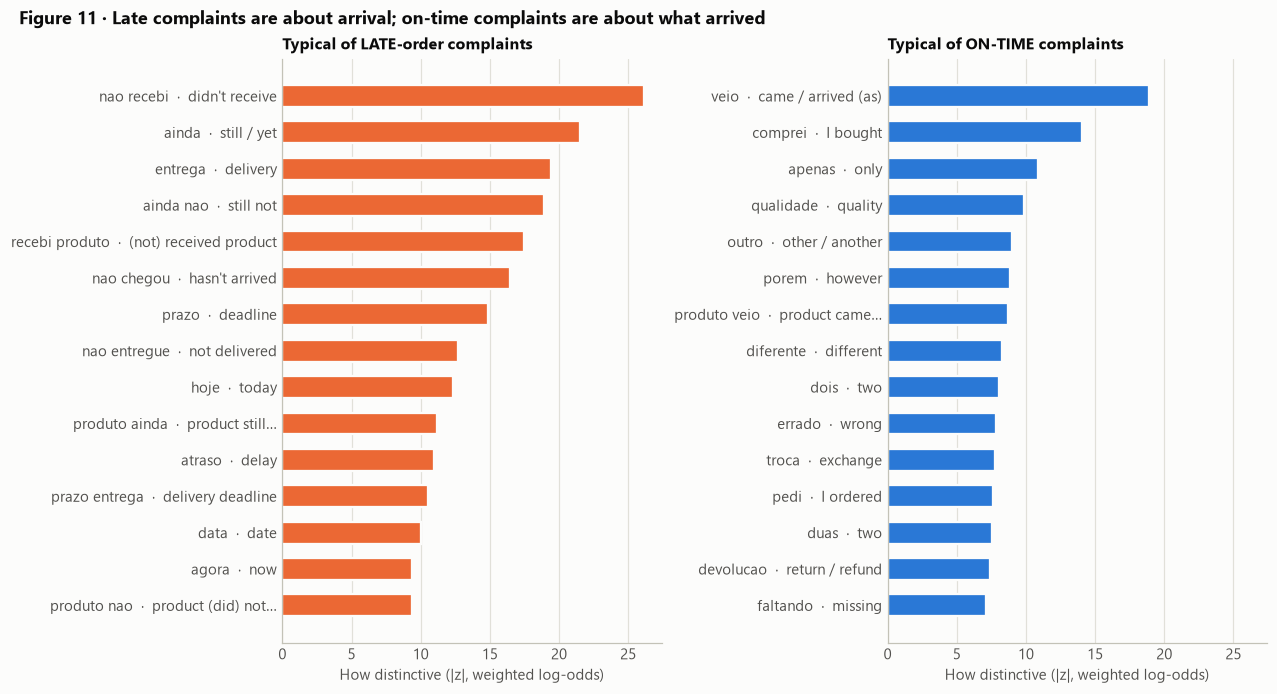

,term,z,share_of_late_complaints,share_of_on_time_complaints,gloss
289,nao recebi,26.1,30.9%,8.5%,didn't receive
162,ainda,21.6,23.8%,6.8%,still / yet
278,entrega,19.4,21.8%,6.8%,delivery
134,ainda nao,18.9,16.2%,3.6%,still not
426,recebi produto,17.4,19.5%,6.5%,(not) received product
116,nao chegou,16.4,11.2%,2.0%,hasn't arrived
392,prazo,14.8,14.4%,4.6%,deadline
174,nao entregue,12.7,9.3%,2.5%,not delivered
298,hoje,12.3,5.9%,0.8%,today
244,produto ainda,11.2,5.0%,0.7%,product still…


In [14]:
STOP = set("""a o e de da do das dos em no na nos nas um uma uns umas para pra pro por com como que se ao aos ou mas mais
foi ser era sao esta estao isso esse essa este aqui ja me meu minha meus minhas eu voce voces ele ela eles elas lhe muito
muita bem so tambem ate pelo pela pelos pelas sobre entre quando onde porque pois tem ter tinha dia dias vez nem sim seu
sua seus suas nosso nossa loja lannister stark targaryen baratheon martell tyrell arryn tully greyjoy""".split())


def tokens(text):
    text = unicodedata.normalize("NFKD", str(text).lower())
    return re.findall(r"[a-z]+", "".join(ch for ch in text if not unicodedata.combining(ch)))


def grams(text):
    toks = [t for t in tokens(text) if t not in STOP]  # "nao" (not) is kept on purpose
    return set([t for t in toks if t != "nao"] + [f"{a} {b}" for a, b in zip(toks, toks[1:])])


neg_text = d[d.negative & d.has_text]
late_docs, on_docs = neg_text[neg_text.is_late], neg_text[~neg_text.is_late]
c_late = Counter(g for t in late_docs.review_comment_message for g in grams(t))
c_on = Counter(g for t in on_docs.review_comment_message for g in grams(t))
vocab = [g for g in set(c_late) | set(c_on) if c_late[g] + c_on[g] >= 40]
total, a0 = sum(c_late[g] + c_on[g] for g in vocab), 500
n_l, n_o = len(late_docs), len(on_docs)
rows = []
for g in vocab:
    prior = a0 * (c_late[g] + c_on[g]) / total
    delta = (np.log((c_late[g] + prior) / (n_l + a0 - c_late[g] - prior))
             - np.log((c_on[g] + prior) / (n_o + a0 - c_on[g] - prior)))
    rows.append((g, delta / np.sqrt(1 / (c_late[g] + prior) + 1 / (c_on[g] + prior)), c_late[g] / n_l, c_on[g] / n_o))
terms = pd.DataFrame(rows, columns=["term", "z", "share_of_late_complaints", "share_of_on_time_complaints"]).sort_values("z")

GLOSS = {"nao recebi": "didn't receive", "ainda": "still / yet", "entrega": "delivery", "ainda nao": "still not",
         "recebi produto": "(not) received product", "nao chegou": "hasn't arrived", "prazo": "deadline",
         "nao entregue": "not delivered", "hoje": "today", "produto ainda": "product still…", "atraso": "delay",
         "prazo entrega": "delivery deadline", "veio": "came / arrived (as)", "comprei": "I bought", "apenas": "only",
         "qualidade": "quality", "outro": "other / another", "porem": "however", "produto veio": "product came…",
         "diferente": "different", "dois": "two", "errado": "wrong", "troca": "exchange", "pedi": "I ordered",
         "duas": "two", "devolucao": "return / refund", "faltando": "missing", "somente": "only",
         "recebi apenas": "received only", "defeito": "defect", "data": "date", "agora": "now",
         "produto nao": "product (did) not…"}
TOP_N = 15
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.2), sharex=True, layout="constrained")
for ax, side, color, name in [(axes[0], terms.tail(TOP_N), LATE, "Typical of LATE-order complaints"),
                              (axes[1], terms.head(TOP_N), ONTIME, "Typical of ON-TIME complaints")]:
    side = side.sort_values("z", key=abs)
    ax.barh([f"{t}  ·  {GLOSS.get(t, '')}" for t in side.term], side.z.abs(), height=0.6, color=color, **BAR)
    ax.set_title(name)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.set_xlabel("How distinctive (|z|, weighted log-odds)")
title(fig, "Figure 11 · Late complaints are about arrival; on-time complaints are about what arrived")
plt.show()
show(pd.concat([terms.tail(TOP_N)[::-1], terms.head(TOP_N)]).assign(gloss=lambda x: x.term.map(GLOSS)),
     pct=["share_of_late_complaints", "share_of_on_time_complaints"], num=["z"], dec=1)

In [15]:
PATTERNS = {
    "says 'not received / still not arrived'": r"(nao recebi|ainda nao|nao chegou|nao foi entregue|nao entregue)",
    "says 'only part / missing item'": r"(apenas|somente|faltou|faltando|so veio|so recebi|um dos|uma das|outro produto)",
    "says 'wrong / different / defective / broken'": r"(errad|diferente|defeito|quebrad|danificad|trocad|nao funciona)",
}
segments = {
    "Late orders": neg_text[neg_text.is_late],
    "On-time orders": neg_text[~neg_text.is_late],
    "On-time, 2+ sellers": neg_text[~neg_text.is_late & (neg_text.n_sellers >= 2)],
    "On-time, 1 seller": neg_text[~neg_text.is_late & (neg_text.n_sellers == 1)],
}
mentions = pd.DataFrame({
    seg: {"negative comments": len(frame),
          **{k: frame.review_comment_message.map(lambda t: " ".join(tokens(t))).str.contains(p).mean()
             for k, p in PATTERNS.items()}}
    for seg, frame in segments.items()}).T
print(f"Share of on-time negative reviews that include a comment: {on.loc[on.negative, 'has_text'].mean():.1%}")
show(mentions.reset_index(names="1–2★ comments from…"), pct=list(PATTERNS), num=["negative comments"])

examples = ["chegou 1 dos dois", "cabides do mesmo pedido", "caixa do Pet na cor azul", "um dos produtos veio danificado",
            "primeiro dia que utilizei", "nota ZERO"]
ex = pd.concat([on[on.negative & on.review_comment_message.str.contains(e, na=False, regex=False)].head(1) for e in examples])
display(ex[["review_score", "n_sellers", "n_items", "days_vs_estimate", "review_comment_message"]].reset_index(drop=True))

Share of on-time negative reviews that include a comment: 78.3%


,1–2★ comments from…,negative comments,says 'not received / still not arrived',says 'only part / missing item',says 'wrong / different / defective / broken'
0,Late orders,"2,747",52.4%,3.7%,2.0%
1,On-time orders,"6,487",13.9%,20.3%,17.9%
2,"On-time, 2+ sellers",497,36.2%,51.9%,4.4%
3,"On-time, 1 seller","5,990",12.1%,17.7%,19.0%


,review_score,n_sellers,n_items,days_vs_estimate,review_comment_message
0,2,2.0,2.0,-19,Só chegou 1 dos dois produtos comprados\r\n\r\nNo caso chegou o BCAA e falta o hemo rage black
1,1,2.0,4.0,-12,"as araras são boas, mas não recebi os cabides do mesmo pedido."
2,1,1.0,1.0,-13,"Recebi o material bem antes do prazo informado, mas fiz o pedido para receber a caixa do Pet na cor azul e entregaram na cor rosa."
3,2,1.0,2.0,-15,O produto foi entregue dentro do prazo porém um dos produtos veio danificado.
4,1,1.0,1.0,-8,No primeiro dia que utilizei o produto o mesmo já não funcionou.
5,1,1.0,1.0,-19,"Loja excelente, mas o produto é nota ZERO. Nem fiz questão de tirar da embalagem. Joguei direto no lixo."


**What we see.**
- Late complaints are about **arrival**: *não recebi* (didn't receive), *ainda não* (still not), *prazo* (deadline), *atraso* (delay). About half say the parcel had not arrived.
- On-time complaints are about **what arrived**: *veio* (it came [wrong/broken]), *apenas / faltando* (only / missing), *errado / diferente* (wrong / different), *qualidade* (quality), *troca / devolução* (exchange / return). 19% of single-seller on-time complaints say the item was wrong, different, defective or broken, against 2% of late complaints.
- In **multi-seller on-time orders, 52% of complaints say only part of the order arrived**. The order-level "delivered" timestamp probably marks the *first* parcel, so part of this "on-time" group was in fact only partly delivered.

Example comments, all from orders delivered on time (from the table above):

| Comment (Portuguese) | English |
|---|---|
| *Só chegou 1 dos dois produtos comprados* | Only 1 of the 2 products I bought arrived |
| *as araras são boas, mas não recebi os cabides do mesmo pedido* | The racks are good, but I didn't receive the hangers from the same order |
| *Recebi o material bem antes do prazo informado, mas fiz o pedido … na cor azul e entregaram na cor rosa* | It arrived well before the promised date, but I ordered blue and they delivered pink |
| *O produto foi entregue dentro do prazo porém um dos produtos veio danificado* | Delivered on time, but one of the products arrived damaged |
| *No primeiro dia que utilizei o produto o mesmo já não funcionou* | It stopped working on the first day I used it |
| *Loja excelente, mas o produto é nota ZERO … Joguei direto no lixo* | Great store, but the product gets a zero … I threw it straight in the bin |

**Why it matters.** These failures are **order accuracy, order condition and product quality**, dimensions of logistics service quality that go beyond timeliness (Mentzer, Flint & Hult 2001; Rao et al. 2011), plus split deliveries (Brylla & Walsh 2022). None of them can be seen in `days_vs_estimate`.

## 5 · Summary

### Why published Olist models predict lateness
| # | Reason | Evidence in this notebook |
|---|---|---|
| 1 | Lateness is the loudest signal and acts like a cliff | 62.4% vs 9.3% negative (6.7×); 50% negative only three days past the promised date (Fig. 2) |
| 2 | For late orders the label is partly produced by the survey schedule | 70% of late-order reviews were written before the parcel arrived; 81% of those are negative (Fig. 3) |
| 3 | Lateness drives the time trend | Monthly negative-rate spikes line up with late-share spikes; the on-time rate stays at 7–11% (Fig. 4) |
| 4 | Timing features top every ranking when all orders are pooled | Top-4 single-feature AUCs are timing features; `days_vs_estimate` dominates permutation importance (Figs. 5–6) |
| 5 | Accuracy hides the problem | 89.8% accuracy vs an 87.2% do-nothing baseline; the top-10% list catches 96.5% of late negatives but only 16.7% of on-time negatives (Fig. 7) |

### What that leaves out: on-time but unhappy
- **67.5% of all negative reviews** (8,289 orders) come from on-time orders (Fig. 8).
- Their risk factors are **split and multi-item orders** (2 sellers → 46% negative), **long waits and long promises**, **weak seller track records**, **late dispatch**, and certain **categories** (Figs. 9–10).
- Their complaints are about **missing, wrong, damaged or poor-quality items**, not about arrival (Fig. 11).

### Implications for the Hidden Dissatisfaction model
1. **Population:** train and evaluate on on-time delivered orders only (9.3% positives). That is the dashboard's scope, and it stops lateness from swamping everything else.
2. **Features first:** `n_sellers`, `n_items`, `n_products`, point-in-time seller history, delivery and promised duration, `dispatch_late`, category, price and freight. All are known at delivery.
3. **No leakage:** review text, review timestamps and "answered before delivery" are post-outcome. Use them only to understand the label, or to build a complaint-type label later (partial delivery / wrong item / quality).
4. **Metrics:** PR-AUC, precision and recall at the contact budget (top-k), and a calibration check. Never accuracy alone. If you rebalance classes, recalibrate: resampling distorts the 0–100% risk score (van den Goorbergh et al. 2022; Dal Pozzolo et al. 2015).
5. **Validation:** use a **time-based** split (e.g. train on purchases up to Mar 2018, test on Apr–Aug 2018). The diagnostic models above used a random split *only* to mirror the published papers.

### Caveats
- Everything here is **association, not causation**.
- "Late" uses Olist's estimated date at day granularity. If Olist revised that estimate during shipping, the data does not show it.
- For multi-seller orders the order-level delivery timestamp likely refers to one parcel, so some "on-time" multi-seller orders were only partly delivered. This is a data-definition issue as well as a behavioural one.
- Seller history needs at least 5 earlier answered reviews; 84% of orders have it.
- The diagnostic gradient-boosting numbers are illustrative (default settings, random split), not benchmarks.